<a href="https://colab.research.google.com/github/eliezana05/-DI-Bootcamp-Stage1/blob/main/Week3/Day1/Daily_Challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
City,,,,,,,,,,,,
Paris,25.96,12.56,29.34,22.89,-1.23,34.02,25.45,26.44,0.12,13.02,9.83,32.07
London,20.75,27.91,12.74,4.09,17.18,-2.45,28.11,20.27,25.32,9.18,33.83,30.72
Tokyo,26.14,2.79,13.67,-3.25,1.17,22.32,24.79,33.70,8.03,9.82,13.78,2.58
New York,0.20,14.03,4.08,21.79,12.49,28.31,23.01,7.49,28.29,27.19,10.50,6.53
Tel Aviv,22.30,0.59,3.00,-4.71,26.48,21.59,23.21,26.23,13.36,17.75,0.59,-0.42
Sydney,21.74,13.84,17.61,25.60,20.39,17.14,17.37,7.16,-3.77,12.47,3.58,11.34
Cairo,29.14,4.36,-2.67,6.26,6.74,21.48,17.28,26.36,21.57,11.26,27.56,1.68
Toronto,-4.09,-1.40,23.89,13.48,1.45,15.04,1.09,22.85,12.85,10.24,7.06,20.21
Berlin,9.47,-1.49,-0.28,33.48,31.34,22.99,5.63,33.77,26.15,23.68,12.97,5.89


,Annual mean (°C)
City,
Paris,19.21
London,18.97
Berlin,16.97
Madrid,15.38
New York,15.33
Cairo,14.25
Sydney,13.71
Tokyo,12.96
Tel Aviv,12.50


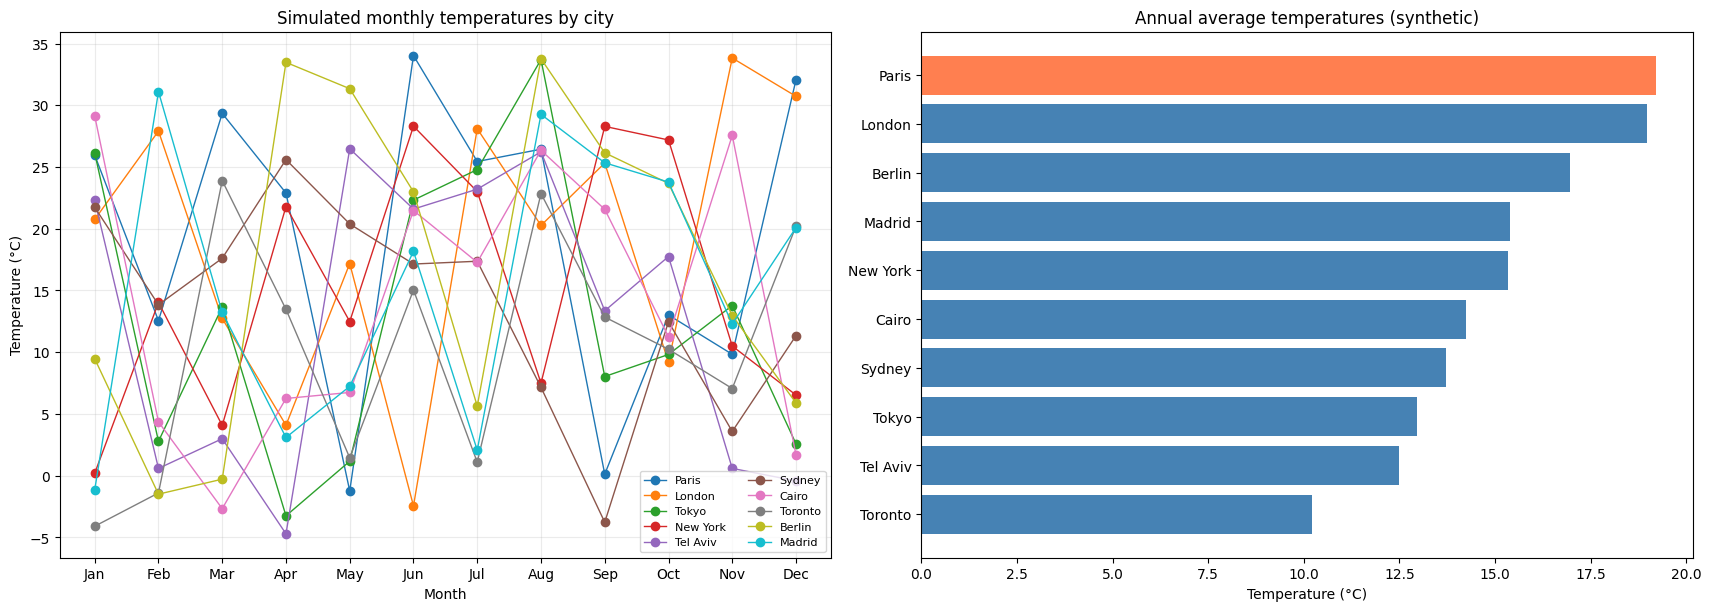

### Findings
- Highest annual average: **Paris**, **19.21 °C**.
- Lowest annual average: **Toronto**, **10.22 °C**.
- Difference between those annual means: **8.98 °C**.
- Across cities, the warmest simulated month is **Aug** (23.35 °C); the coolest is **Feb** (10.43 °C).
- Month-to-month variability is random. Independent uniform sampling does not model seasonality, geography or the different hemispheres. These results illustrate analysis techniques and do not support conclusions about actual climates.


Data generation and analysis checks passed.


In [1]:
# Daily Challenge — NumPy, Pandas and Matplotlib Integration
# Synthetic data: these values are simulated, not real weather observations.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

rng = np.random.default_rng(42)
cities = ['Paris', 'London', 'Tokyo', 'New York', 'Tel Aviv', 'Sydney', 'Cairo', 'Toronto', 'Berlin', 'Madrid']
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
temperatures = rng.uniform(-5, 35, size=(10, 12))
weather = pd.DataFrame(temperatures, index=cities, columns=months)
weather.index.name = 'City'
annual_average = weather.mean(axis=1)
hottest_city = annual_average.idxmax()
coldest_city = annual_average.idxmin()
display(weather.round(2))
display(annual_average.rename('Annual mean (°C)').sort_values(ascending=False).to_frame().round(2))

fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)
for city in cities:
    axes[0].plot(months, weather.loc[city], marker='o', linewidth=1, label=city)
axes[0].set(title='Simulated monthly temperatures by city', xlabel='Month', ylabel='Temperature (°C)')
axes[0].grid(alpha=0.25)
axes[0].legend(fontsize=8, ncol=2)
ordered = annual_average.sort_values()
axes[1].barh(ordered.index, ordered.values, color=['steelblue' if city != hottest_city else 'coral' for city in ordered.index])
axes[1].set(title='Annual average temperatures (synthetic)', xlabel='Temperature (°C)')
plt.show()

monthly_average = weather.mean(axis=0)
display(Markdown(f'''### Findings
- Highest annual average: **{hottest_city}**, **{annual_average[hottest_city]:.2f} °C**.
- Lowest annual average: **{coldest_city}**, **{annual_average[coldest_city]:.2f} °C**.
- Difference between those annual means: **{annual_average.max() - annual_average.min():.2f} °C**.
- Across cities, the warmest simulated month is **{monthly_average.idxmax()}** ({monthly_average.max():.2f} °C); the coolest is **{monthly_average.idxmin()}** ({monthly_average.min():.2f} °C).
- Month-to-month variability is random. Independent uniform sampling does not model seasonality, geography or the different hemispheres. These results illustrate analysis techniques and do not support conclusions about actual climates.
'''))
assert weather.shape == (10, 12)
assert weather.notna().all().all()
assert np.all((temperatures >= -5) & (temperatures <= 35))
np.testing.assert_allclose(annual_average.to_numpy(), temperatures.sum(axis=1) / 12)
assert annual_average[hottest_city] >= annual_average[coldest_city]
print('Data generation and analysis checks passed.')
